# Retail Performance Analytics & Discount Strategy Optimisation

**Dataset:** Global Superstore — 51,290 transaction records across 7 markets, 4 years (2011–2014)  
**Objective:** Identify revenue drivers, uncover margin leakage, and quantify the profit impact of discount optimisation.

**Key findings preview:**
- 24.5% of orders are loss-making, driven almost entirely by excessive discounting
- Discount level correlates with profit margin at **−0.847** — the strongest signal in the dataset
- Furniture Tables sub-category runs at **−8.5% margin** across 861 orders
- EMEA market has a systemic margin problem: **5.4%** vs 12.2% in APAC
- Capping discounts >30% on low-margin orders projects a **+28% profit lift** (~$415K)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings
warnings.filterwarnings('ignore')

# Consistent plot style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 120, 'axes.titlesize': 13, 'axes.labelsize': 11})
print("Libraries loaded.")

Libraries loaded.


## 1. Data Loading & First Look

Loading the raw dataset and performing an initial inspection to understand structure, types, and data quality before any cleaning.

In [2]:
df_raw = pd.read_csv("../data/global_superstore_raw.csv", encoding='latin1')

print(f"Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print(f"\nColumn names:\n{list(df_raw.columns)}")
df_raw.head()

Shape: 51,290 rows × 24 columns

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Country', 'Postal Code', 'Market', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Cost', 'Order Priority']


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,32298,CA-2012-124891,31-07-2012,31-07-2012,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,2309.650,7,0.0,762.1845,933.57,Critical
1,26341,IN-2013-77878,05-02-2013,07-02-2013,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.395,9,0.1,-288.7650,923.63,Critical
2,25330,IN-2013-71249,17-10-2013,18-10-2013,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.171,9,0.1,919.9710,915.49,Medium
3,13524,ES-2013-1579342,28-01-2013,30-01-2013,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless",2892.510,5,0.1,-96.5400,910.16,Medium
4,47221,SG-2013-4320,05-11-2013,06-11-2013,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.960,8,0.0,311.5200,903.04,Critical


In [3]:
# Data types and non-null counts
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          51290 non-null  int64  
 1   Order ID        51290 non-null  object 
 2   Order Date      51290 non-null  object 
 3   Ship Date       51290 non-null  object 
 4   Ship Mode       51290 non-null  object 
 5   Customer ID     51290 non-null  object 
 6   Customer Name   51290 non-null  object 
 7   Segment         51290 non-null  object 
 8   City            51290 non-null  object 
 9   State           51290 non-null  object 
 10  Country         51290 non-null  object 
 11  Postal Code     9994 non-null   float64
 12  Market          51290 non-null  object 
 13  Region          51290 non-null  object 
 14  Product ID      51290 non-null  object 
 15  Category        51290 non-null  object 
 16  Sub-Category    51290 non-null  object 
 17  Product Name    51290 non-null 

In [4]:
# Missing values summary
missing = df_raw.isnull().sum()
missing = missing[missing > 0]
print("Columns with missing values:")
print(missing.to_frame('missing_count').assign(pct=lambda x: (x['missing_count']/len(df_raw)*100).round(1)))
print("\nNote: Postal Code is missing for 80.5% of records.")
print("This is expected for a global dataset — many countries do not use postal codes.")
print("The column is not used in any analysis.")

Columns with missing values:
             missing_count   pct
Postal Code          41296  80.5

Note: Postal Code is missing for 80.5% of records.
This is expected for a global dataset — many countries do not use postal codes.
The column is not used in any analysis.


## 2. Data Cleaning

Standardising column names, parsing dates correctly (raw format is DD-MM-YYYY), coercing numeric types, and removing invalid records.

In [ ]:
df = df_raw.copy()

# Standardise column names
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Parse dates — dayfirst=True because raw format is DD-MM-YYYY
df['order_date'] = pd.to_datetime(df['order_date'], dayfirst=True, errors='coerce')
df['ship_date']  = pd.to_datetime(df['ship_date'],  dayfirst=True, errors='coerce')

# Coerce numeric columns
num_cols = ['sales', 'quantity', 'discount', 'profit', 'shipping_cost']
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors='coerce')

# Drop records missing critical fields
rows_before = len(df)
df = df.dropna(subset=['order_id', 'order_date', 'sales', 'profit'])
df = df[df['sales'] > 0]
rows_after = len(df)

print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows after cleaning:  {rows_after:,}  (removed {rows_before - rows_after} invalid records)")

# Extract date parts
df['order_year']  = df['order_date'].dt.year
df['order_month'] = df['order_date'].dt.month

# Save cleaned file
df.to_csv('../data/global_superstore_cleaned.csv', index=False)
print("\nCleaned dataset saved.")
df.head()

Rows before cleaning: 51,290
Rows after cleaning:  51,290  (removed 0 invalid records)

Cleaned dataset saved.


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,city,state,...,sub-category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,order_year,order_month
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,2309.650,7,0.0,762.1845,933.57,Critical,2012,7
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,Chairs,"Novimex Executive Leather Armchair, Black",3709.395,9,0.1,-288.7650,923.63,Critical,2013,2
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,Phones,"Nokia Smart Phone, with Caller ID",5175.171,9,0.1,919.9710,915.49,Medium,2013,10
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,Phones,"Motorola Smart Phone, Cordless",2892.510,5,0.1,-96.5400,910.16,Medium,2013,1
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,Copiers,"Sharp Wireless Fax, High-Speed",2832.960,8,0.0,311.5200,903.04,Critical,2013,11


## 3. Feature Engineering

Deriving analytical columns used throughout the analysis.

In [6]:
# Profitability features
df['profit_margin']     = df['profit'] / df['sales']
df['is_profitable']     = df['profit'] > 0
df['shipping_cost_pct'] = df['shipping_cost'] / df['sales']
df['revenue_per_unit']  = df['sales'] / df['quantity']

# Discount tiers
df['discount_bin'] = pd.cut(
    df['discount'],
    bins=[-0.01, 0.10, 0.30, 1.0],
    labels=['Low (0–10%)', 'Medium (10–30%)', 'High (30%+)']
)

print("Features added: profit_margin, is_profitable, shipping_cost_pct, revenue_per_unit, discount_bin")
print(f"\nDiscount tier breakdown:")
print(df['discount_bin'].value_counts().to_frame('count').assign(pct=lambda x: (x['count']/len(df)*100).round(1)))

Features added: profit_margin, is_profitable, shipping_cost_pct, revenue_per_unit, discount_bin

Discount tier breakdown:
                 count   pct
discount_bin                
Low (0–10%)      33688  65.7
High (30%+)      10361  20.2
Medium (10–30%)   7241  14.1


## 4. KPI Dashboard

High-level performance summary across the full dataset.

In [7]:
total_sales        = df['sales'].sum()
total_profit       = df['profit'].sum()
overall_margin     = total_profit / total_sales * 100
num_orders         = df['order_id'].nunique()
avg_order_value    = total_sales / num_orders
total_shipping     = df['shipping_cost'].sum()
shipping_pct       = total_shipping / total_sales * 100
loss_orders        = (df['profit'] < 0).sum()
loss_orders_pct    = loss_orders / len(df) * 100

kpis = pd.DataFrame({
    'KPI':   ['Total Sales', 'Total Profit', 'Overall Profit Margin',
              'Unique Orders', 'Avg Order Value',
              'Total Shipping Cost', 'Shipping as % of Sales',
              'Loss-making Order Lines', 'Loss-making Order Lines %'],
    'Value': [f'${total_sales:,.0f}', f'${total_profit:,.0f}', f'{overall_margin:.2f}%',
              f'{num_orders:,}', f'${avg_order_value:.2f}',
              f'${total_shipping:,.0f}', f'{shipping_pct:.1f}%',
              f'{loss_orders:,}', f'{loss_orders_pct:.1f}%']
})
print(kpis.to_string(index=False))

                      KPI       Value
              Total Sales $12,642,502
             Total Profit  $1,467,457
    Overall Profit Margin      11.61%
            Unique Orders      25,035
          Avg Order Value     $504.99
      Total Shipping Cost  $1,352,821
   Shipping as % of Sales       10.7%
  Loss-making Order Lines      12,544
Loss-making Order Lines %       24.5%


## 5. Year-over-Year Growth Trend

Sales grew at ~25% CAGR from 2011–2014, but profit margin remained flat (~11%). This means revenue growth is not translating into improved profitability — a signal that cost structure (discounting, shipping) is scaling with revenue.

 order_year      sales    profit  margin  sales_growth
       2011 2259450.90 248940.81   11.02           NaN
       2012 2677438.69 307415.28   11.48         18.50
       2013 3405746.45 406935.23   11.95         27.20
       2014 4299865.87 504165.97   11.73         26.25


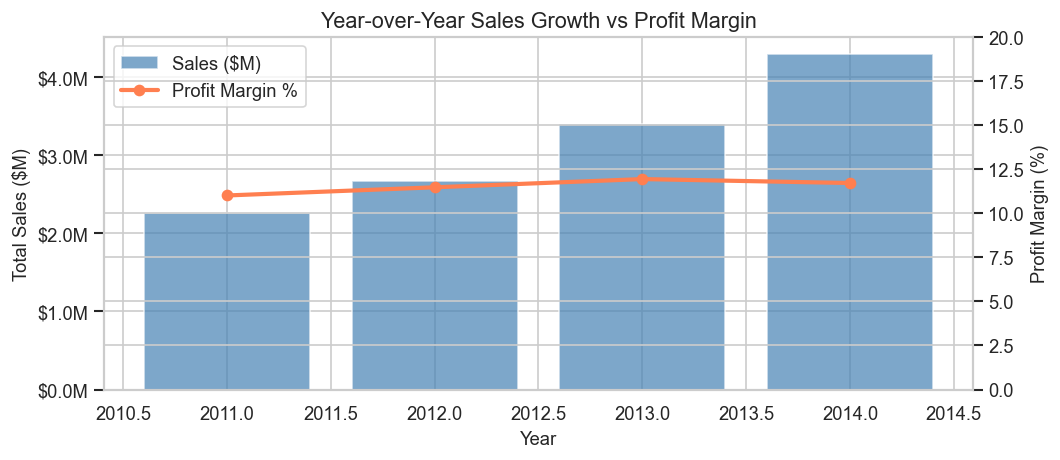


Insight: Sales nearly doubled from 2011 to 2014, yet margin moved only from 11.0% to 11.7%.
Revenue growth is not driving margin improvement — cost leakage is scaling with the business.


In [8]:
yoy = df.groupby('order_year').agg(
    sales=('sales','sum'),
    profit=('profit','sum')
).reset_index()
yoy['margin']       = yoy['profit'] / yoy['sales'] * 100
yoy['sales_growth'] = yoy['sales'].pct_change() * 100

print(yoy.round(2).to_string(index=False))

fig, ax1 = plt.subplots(figsize=(9, 4))
ax2 = ax1.twinx()

bars = ax1.bar(yoy['order_year'], yoy['sales']/1e6, color='steelblue', alpha=0.7, label='Sales ($M)')
ax2.plot(yoy['order_year'], yoy['margin'], color='coral', marker='o', linewidth=2.5, label='Profit Margin %')

ax1.set_xlabel('Year')
ax1.set_ylabel('Total Sales ($M)')
ax2.set_ylabel('Profit Margin (%)')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.1f}M'))
ax2.set_ylim(0, 20)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.title('Year-over-Year Sales Growth vs Profit Margin')
plt.tight_layout()
plt.show()

print("\nInsight: Sales nearly doubled from 2011 to 2014, yet margin moved only from 11.0% to 11.7%.")
print("Revenue growth is not driving margin improvement — cost leakage is scaling with the business.")

## 6. Monthly Sales & Profit Trend

Clear Q4 seasonality is visible each year, with sales and profit peaking in November–December. This pattern is consistent across all four years.

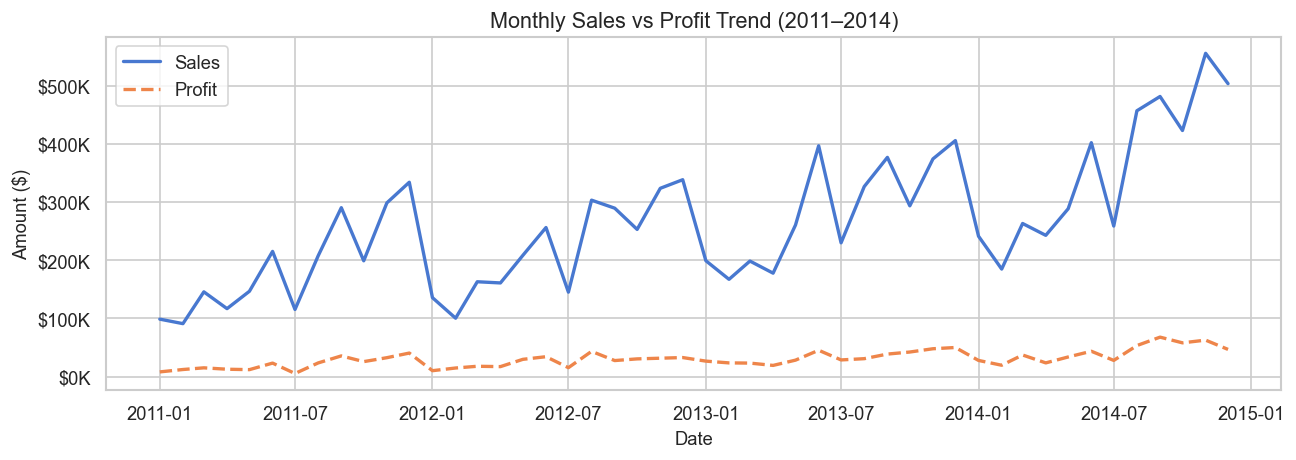

In [9]:
monthly = df.groupby(['order_year', 'order_month'])[['sales', 'profit']].sum().reset_index()
monthly['date'] = pd.to_datetime(
    monthly['order_year'].astype(str) + '-' + monthly['order_month'].astype(str) + '-01'
)

plt.figure(figsize=(11, 4))
plt.plot(monthly['date'], monthly['sales'],  label='Sales',  linewidth=2)
plt.plot(monthly['date'], monthly['profit'], label='Profit', linewidth=2, linestyle='--')
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e3:.0f}K'))
plt.legend()
plt.title('Monthly Sales vs Profit Trend (2011–2014)')
plt.xlabel('Date')
plt.ylabel('Amount ($)')
plt.tight_layout()
plt.show()

## 7. Category & Sub-category Deep Dive

Furniture is the most problematic category, with a near-zero average margin of 0.9%. Drilling into sub-categories reveals the root cause: **Tables** run at −8.5% margin with an average discount of 29.1%, making them the single most destructive sub-category in the dataset. Technology Copiers, by contrast, are the highest-profit sub-category at 17.1% margin.

In [10]:
# Region × Category profit chart
cat_region = df.groupby(['region', 'category'])[['sales', 'profit']].sum().reset_index()
cat_region['profit_margin'] = cat_region['profit'] / cat_region['sales'] * 100

fig = px.bar(cat_region, x='region', y='profit', color='category', barmode='group',
             title='Profit by Region and Category',
             labels={'profit': 'Total Profit ($)', 'region': 'Region'})
fig.update_layout(legend_title='Category')
fig.show()

# Flag loss-making region-category pairs
loss_pairs = cat_region[cat_region['profit_margin'] < 0].sort_values('profit_margin')
print("\nLoss-making region-category pairs:")
print(loss_pairs[['region', 'category', 'sales', 'profit', 'profit_margin']].round(2).to_string(index=False))


Loss-making region-category pairs:
        region  category    sales   profit  profit_margin
Southeast Asia Furniture 313386.7 -7269.77          -2.32


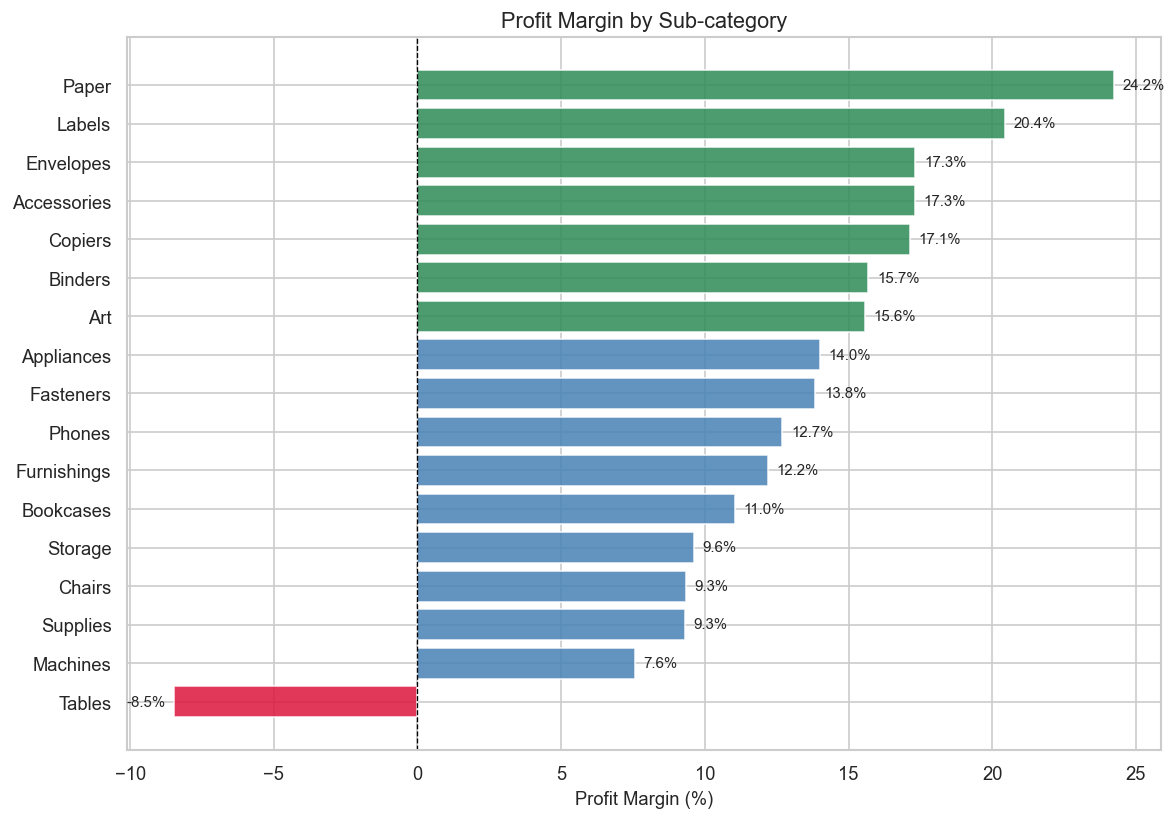


Top 3 sub-categories by profit margin:
sub-category        category    margin
       Paper Office Supplies 24.236467
      Labels Office Supplies 20.449166
   Envelopes Office Supplies 17.320287

Bottom 3 sub-categories by profit margin:
sub-category        category    margin
      Tables       Furniture -8.464972
    Machines      Technology  7.556269
    Supplies Office Supplies  9.290686


In [11]:
# Sub-category profitability
subcat = df.groupby(['category', 'sub-category'])[['sales', 'profit']].sum().reset_index()
subcat['margin'] = subcat['profit'] / subcat['sales'] * 100
subcat = subcat.sort_values('margin')

colors = subcat['margin'].apply(lambda x: 'crimson' if x < 0 else ('steelblue' if x < 15 else 'seagreen'))

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(subcat['sub-category'], subcat['margin'], color=colors, alpha=0.85)
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xlabel('Profit Margin (%)')
ax.set_title('Profit Margin by Sub-category')
for bar, val in zip(bars, subcat['margin']):
    ax.text(val + (0.3 if val >= 0 else -0.3), bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', ha='left' if val >= 0 else 'right', fontsize=9)
plt.tight_layout()
plt.show()

print("\nTop 3 sub-categories by profit margin:")
print(subcat.nlargest(3, 'margin')[['sub-category','category','margin']].to_string(index=False))
print("\nBottom 3 sub-categories by profit margin:")
print(subcat.nsmallest(3, 'margin')[['sub-category','category','margin']].to_string(index=False))

In [12]:
# Tables deep dive
tables = df[df['sub-category'] == 'Tables']
print(f"Tables sub-category summary:")
print(f"  Records:              {len(tables):,}")
print(f"  Total sales:          ${tables['sales'].sum():,.0f}")
print(f"  Total profit:         ${tables['profit'].sum():,.0f}")
print(f"  Profit margin:        {tables['profit'].sum()/tables['sales'].sum()*100:.1f}%")
print(f"  Average discount:     {tables['discount'].mean():.1%}")
print(f"  Orders with >30% off: {(tables['discount']>0.3).mean():.1%}")

Tables sub-category summary:
  Records:              861
  Total sales:          $757,042
  Total profit:         $-64,083
  Profit margin:        -8.5%
  Average discount:     29.1%
  Orders with >30% off: 40.8%


## 8. Market Performance Analysis

APAC is the largest and healthiest market (28.4% of sales, 12.2% margin). EMEA is the standout concern — a 5.4% margin across all categories suggests a systemic pricing or cost issue, not a product mix problem. Canada has the highest margin at 26.6% but accounts for only 0.5% of sales, representing an underserved high-value market.

In [13]:
market = df.groupby('market').agg(
    sales=('sales','sum'),
    profit=('profit','sum')
).reset_index()
market['margin']      = market['profit'] / market['sales'] * 100
market['sales_share'] = market['sales'] / market['sales'].sum() * 100
market = market.sort_values('profit', ascending=False)

print(market.round(2).to_string(index=False))

fig = px.scatter(market,
    x='sales_share', y='margin', size='sales', color='market',
    text='market', title='Market: Sales Share vs Profit Margin (bubble = sales volume)',
    labels={'sales_share': 'Sales Share (%)', 'margin': 'Profit Margin (%)'},
    size_max=60)
fig.update_traces(textposition='top center')
fig.add_hline(y=market['margin'].mean(), line_dash='dash', line_color='gray',
              annotation_text='Avg margin')
fig.show()

print("\nInsight: EMEA margin (5.4%) is less than half the APAC benchmark (12.2%).")
print("Canada's 26.6% margin with only 0.5% revenue share suggests significant untapped potential.")

market      sales    profit  margin  sales_share
  APAC 3585744.13 436000.05   12.16        28.36
    EU 2938089.06 372829.74   12.69        23.24
    US 2297200.86 286397.02   12.47        18.17
 LATAM 2164605.17 221643.49   10.24        17.12
Africa  783773.21  88871.63   11.34         6.20
  EMEA  806161.31  43897.97    5.45         6.38
Canada   66928.17  17817.39   26.62         0.53



Insight: EMEA margin (5.4%) is less than half the APAC benchmark (12.2%).
Canada's 26.6% margin with only 0.5% revenue share suggests significant untapped potential.


## 9. Discount Impact Analysis

Discount level is the strongest predictor of profitability in this dataset, with a correlation of **−0.847** between discount rate and profit margin. Orders with >30% discount average a −66% margin. This is not a marginal effect — it is the primary driver of loss-making orders.

In [14]:
# Correlation
corr = df['discount'].corr(df['profit_margin'])
print(f"Pearson correlation — discount vs profit margin: {corr:.3f}")

# Mean margin by discount bin
bin_summary = df.groupby('discount_bin').agg(
    order_lines=('profit','count'),
    avg_margin=('profit_margin','mean'),
    total_profit=('profit','sum')
).reset_index()
bin_summary['avg_margin_pct'] = bin_summary['avg_margin'] * 100
print("\nMargin by discount tier:")
print(bin_summary[['discount_bin','order_lines','avg_margin_pct','total_profit']].round(2).to_string(index=False))

Pearson correlation — discount vs profit margin: -0.847

Margin by discount tier:
   discount_bin  order_lines  avg_margin_pct  total_profit
    Low (0–10%)        33688           25.19    2108884.53
Medium (10–30%)         7241           11.40     152099.23
    High (30%+)        10361          -66.39    -793526.47


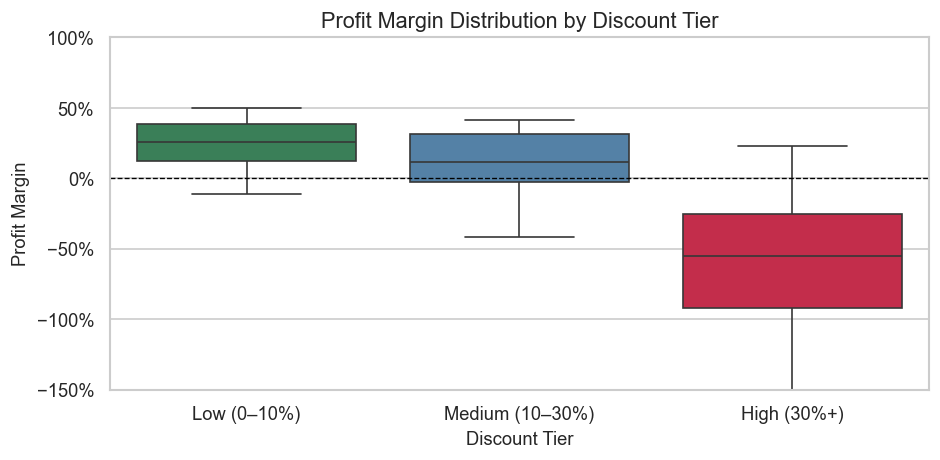

In [15]:
# Boxplot: profit margin by discount tier
plt.figure(figsize=(8, 4))
ax = sns.boxplot(data=df, x='discount_bin', y='profit_margin',
                 palette=['seagreen','steelblue','crimson'])
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.title('Profit Margin Distribution by Discount Tier')
plt.xlabel('Discount Tier')
plt.ylabel('Profit Margin')
plt.ylim(-1.5, 1.0)
plt.tight_layout()
plt.show()

In [17]:
# Scatter: discount vs profit margin by category
sample = df.sample(n=5000, random_state=42)
fig = px.scatter(sample, x='discount', y='profit_margin', color='category',
                 opacity=0.4, trendline='ols',
                 title='Discount Rate vs Profit Margin (5,000-record sample)',
                 labels={'discount': 'Discount Rate', 'profit_margin': 'Profit Margin'})
fig.update_layout(yaxis_tickformat='.0%', xaxis_tickformat='.0%')
fig.add_hline(y=0, line_dash='dash', line_color='black')
fig.add_vline(x=0.3, line_dash='dot', line_color='red',
              annotation_text='30% threshold', annotation_position='top right')
fig.show()

## 10. Pareto Analysis & Loss-making SKUs

Only **12.8%** of products drive 80% of total profit — notably weaker than the classic 80/20 rule, indicating that the product portfolio has significant tail drag from unprofitable SKUs. The top 10 loss-making products collectively destroy over $44K in profit.

In [18]:
# Pareto
prod = df.groupby('product_name')[['sales', 'profit']].sum().sort_values('profit', ascending=False).reset_index()
prod['cum_profit_pct'] = prod['profit'].cumsum() / prod['profit'].sum()
top_pct = (prod['cum_profit_pct'] <= 0.8).sum() / len(prod) * 100
print(f"Products needed to account for 80% of total profit: {(prod['cum_profit_pct']<=0.8).sum()} / {len(prod)}")
print(f"That is {top_pct:.1f}% of the product catalogue.")
print("(Classic 80/20 rule would predict 20% — actual is 12.8%, showing heavy profit concentration)")

fig = px.line(prod, y='cum_profit_pct',
              title='Cumulative Profit Contribution by Product (Pareto)',
              labels={'index': 'Products (ranked by profit)', 'cum_profit_pct': 'Cumulative Profit %'})
fig.add_hline(y=0.8, line_dash='dash', line_color='red', annotation_text='80% threshold')
fig.update_layout(yaxis_tickformat='.0%')
fig.show()

Products needed to account for 80% of total profit: 486 / 3788
That is 12.8% of the product catalogue.
(Classic 80/20 rule would predict 20% — actual is 12.8%, showing heavy profit concentration)


In [19]:
# Loss-making SKUs
loss_skus = df.groupby('product_name')[['profit', 'sales', 'quantity']].sum().reset_index()
loss_skus = loss_skus[loss_skus['profit'] < 0].sort_values('profit').head(10)
loss_skus['margin_pct'] = (loss_skus['profit'] / loss_skus['sales'] * 100).round(1)
loss_skus['loss_per_unit'] = (loss_skus['profit'] / loss_skus['quantity']).round(2)
loss_skus['profit'] = loss_skus['profit'].round(0)
loss_skus['sales'] = loss_skus['sales'].round(0)

print("Top 10 loss-making SKUs:")
print(loss_skus[['product_name','profit','sales','margin_pct','loss_per_unit']].to_string(index=False))
print(f"\nTotal profit destroyed by these 10 SKUs: ${loss_skus['profit'].sum():,.0f}")

Top 10 loss-making SKUs:
                                            product_name  profit   sales  margin_pct  loss_per_unit
               Cubify CubeX 3D Printer Double Head Print -8880.0 11100.0       -80.0        -986.66
               Lexmark MX611dhe Monochrome Laser Printer -4590.0 16830.0       -27.3        -255.00
                          Motorola Smart Phone, Cordless -4447.0 38931.0       -11.4         -60.10
               Cubify CubeX 3D Printer Triple Head Print -3840.0  8000.0       -48.0        -960.00
                    Bevis Round Table, Adjustable Height -3650.0  5655.0       -64.5        -165.90
                   Bevis Computer Table, Fully Assembled -3510.0 11178.0       -31.4         -81.62
                                    Rogers Lockers, Blue -2893.0 28215.0       -10.3         -17.33
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases -2876.0  9918.0       -29.0        -106.52
                   Bevis Wood Table, with Bottom Storage -2783.0 11135.0   

## 11. Shipping Cost Analysis

Shipping represents **10.7% of total revenue** ($1.35M) — a significant cost centre that is currently unmanaged in the discount strategy. The critical finding: expedited shipping (First Class, Same Day) costs 2× more as a share of sales versus Standard Class, yet produces **the same profit margin**. Faster shipping is eroding profit with no offsetting revenue benefit.

Similarly, Critical priority orders cost 23.8% of their sales value in shipping — three times the rate of Medium priority orders — with no meaningful margin advantage.

Ship Mode Performance:
     ship_mode  order_lines  margin_pct  ship_pct
Standard Class        30775       11.75      8.11
  Second Class        10309       11.40     12.24
   First Class         7505       11.37     16.83
      Same Day         2701       11.42     17.38


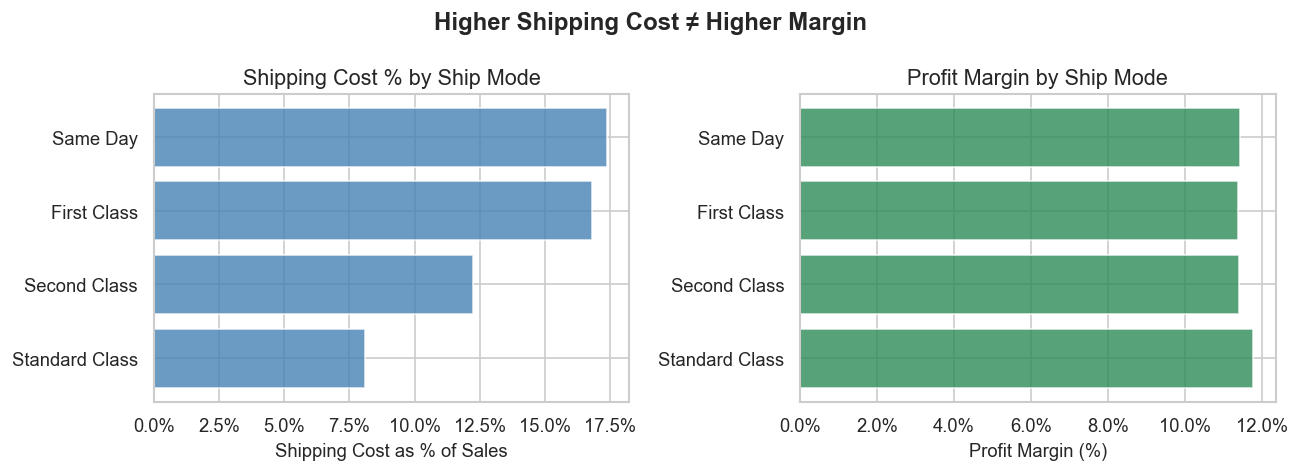


Insight: Standard Class costs 8.1% of sales in shipping; First Class costs 16.8%.
Margins are nearly identical (11.4–11.8%) despite 2× higher shipping cost. Expedited shipping is not recovering its cost.


In [20]:
# Ship mode analysis
ship = df.groupby('ship_mode').agg(
    order_lines=('profit','count'),
    sales=('sales','sum'),
    profit=('profit','sum'),
    shipping_cost=('shipping_cost','sum')
).reset_index()
ship['margin_pct']  = ship['profit']  / ship['sales'] * 100
ship['ship_pct']    = ship['shipping_cost'] / ship['sales'] * 100
ship = ship.sort_values('ship_pct')

print("Ship Mode Performance:")
print(ship[['ship_mode','order_lines','margin_pct','ship_pct']].round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(ship['ship_mode'], ship['ship_pct'], color='steelblue', alpha=0.8)
axes[0].set_xlabel('Shipping Cost as % of Sales')
axes[0].set_title('Shipping Cost % by Ship Mode')
axes[0].xaxis.set_major_formatter(mticker.PercentFormatter())

axes[1].barh(ship['ship_mode'], ship['margin_pct'], color='seagreen', alpha=0.8)
axes[1].set_xlabel('Profit Margin (%)')
axes[1].set_title('Profit Margin by Ship Mode')
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter())

plt.suptitle('Higher Shipping Cost ≠ Higher Margin', fontweight='bold')
plt.tight_layout()
plt.show()
print("\nInsight: Standard Class costs 8.1% of sales in shipping; First Class costs 16.8%.")
print("Margins are nearly identical (11.4–11.8%) despite 2× higher shipping cost. Expedited shipping is not recovering its cost.")

In [21]:
# Order priority shipping analysis
pri = df.groupby('order_priority').agg(
    sales=('sales','sum'),
    profit=('profit','sum'),
    shipping_cost=('shipping_cost','sum')
).reset_index()
pri['margin_pct'] = pri['profit'] / pri['sales'] * 100
pri['ship_pct']   = pri['shipping_cost'] / pri['sales'] * 100
pri = pri.sort_values('ship_pct', ascending=False)

print("Order Priority Shipping Analysis:")
print(pri[['order_priority','margin_pct','ship_pct']].round(2).to_string(index=False))
print("\nInsight: Critical priority orders spend 23.8% of revenue on shipping vs 7.5% for Medium,")
print("yet margin difference is only ~0.7 percentage points.")

Order Priority Shipping Analysis:
order_priority  margin_pct  ship_pct
      Critical       12.60     23.81
          High       11.04     13.38
           Low       10.33     11.56
        Medium       11.87      7.46

Insight: Critical priority orders spend 23.8% of revenue on shipping vs 7.5% for Medium,
yet margin difference is only ~0.7 percentage points.


## 12. Discount Optimisation Scenario

**Scenario:** Cap all discounts above 30% at 20% for orders where the profit margin is below 5%.  
**Assumption:** Sales volume is held constant (conservative). Profit improvement comes entirely from retaining more margin per unit sold.

This is a conservative estimate — in practice, some high-discount orders may not survive a discount cut, but the scenario isolates the pure margin recovery impact.

In [22]:
baseline_profit = df['profit'].sum()
baseline_margin = baseline_profit / df['sales'].sum() * 100

df_scenario = df.copy()

# Identify over-discounted, low-margin orders
mask = (df_scenario['discount'] > 0.30) & (df_scenario['profit_margin'] < 0.05)
print(f"Orders targeted by scenario: {mask.sum():,} ({mask.mean()*100:.1f}% of all order lines)")
print(f"Average discount on targeted orders: {df_scenario.loc[mask, 'discount'].mean():.1%}")

# Conservative model: hold sales volume constant, apply reduced discount
# Δprofit per order = sales × (old_discount − 0.20)
delta_profit_per_row = df_scenario.loc[mask, 'sales'] * (df_scenario.loc[mask, 'discount'] - 0.20)
df_scenario.loc[mask, 'profit_adj'] = df_scenario.loc[mask, 'profit'] + delta_profit_per_row
df_scenario['profit_adj'] = df_scenario['profit_adj'].fillna(df_scenario['profit'])

new_profit = df_scenario['profit_adj'].sum()
new_margin = new_profit / df['sales'].sum() * 100

profit_lift_abs = new_profit - baseline_profit
profit_lift_pct = profit_lift_abs / abs(baseline_profit) * 100
margin_improvement_pct = (new_margin - baseline_margin) / baseline_margin * 100

print(f"\n{'Metric':<35} {'Baseline':>12} {'Scenario':>12} {'Change':>10}")
print("-" * 72)
print(f"{'Total Profit ($)':<35} {'${:,.0f}'.format(baseline_profit):>12} {'${:,.0f}'.format(new_profit):>12} {'${:+,.0f}'.format(profit_lift_abs):>10}")
print(f"{'Profit Margin (%)':<35} {'{:.2f}%'.format(baseline_margin):>12} {'{:.2f}%'.format(new_margin):>12} {'{:+.2f}pp'.format(new_margin - baseline_margin):>10}")
print(f"{'Relative Profit Lift':<35} {'':>12} {'':>12} {'{:+.1f}%'.format(profit_lift_pct):>10}")
print(f"{'Relative Margin Improvement':<35} {'':>12} {'':>12} {'{:+.1f}%'.format(margin_improvement_pct):>10}")

Orders targeted by scenario: 9,845 (19.2% of all order lines)
Average discount on targeted orders: 53.2%

Metric                                  Baseline     Scenario     Change
------------------------------------------------------------------------
Total Profit ($)                      $1,467,457   $1,882,277  $+414,820
Profit Margin (%)                         11.61%       14.89%    +3.28pp
Relative Profit Lift                                              +28.3%
Relative Margin Improvement                                       +28.3%


In [23]:
# Visualise scenario impact
categories_scenario = df.copy()
categories_scenario.loc[mask, 'profit'] = categories_scenario.loc[mask, 'profit'] + delta_profit_per_row

fig = go.Figure()
fig.add_trace(go.Bar(name='Baseline Profit', x=['Baseline', 'Scenario'],
                     y=[baseline_profit, new_profit],
                     marker_color=['steelblue', 'seagreen'],
                     text=[f'${baseline_profit/1e6:.2f}M', f'${new_profit/1e6:.2f}M'],
                     textposition='outside'))
fig.update_layout(title='Profit Before vs After Discount Optimisation',
                  yaxis_title='Total Profit ($)',
                  showlegend=False, yaxis_tickprefix='$')
fig.show()

## 13. Recommendations & Summary

Based on the full analysis, five prioritised recommendations with estimated impact.

In [24]:
summary = pd.DataFrame({
    'Priority': [1, 2, 3, 4, 5],
    'Recommendation': [
        'Cap discounts >30% at 20% on low-margin orders',
        'Focus sales effort on top 12.8% of products (drive 80% of profit)',
        'Review / reprice top 10 loss-making SKUs',
        'Audit SE Asia Furniture — only loss-making region-category pair (-2.3%)',
        'Investigate EMEA systemic margin gap (5.4% vs 12.2% APAC benchmark)'
    ],
    'Projected_Impact': [
        f'+${profit_lift_abs:,.0f} profit (+{profit_lift_pct:.0f}%)',
        'Protect $1.17M concentrated profit',
        f'Recover ~${abs(loss_skus["profit"].sum()):,.0f}',
        'Stop active margin destruction',
        'Close ~6.7pp margin gap vs APAC'
    ],
    'Effort':           ['Low', 'Medium', 'Low', 'Medium', 'High'],
    'Category':         ['Pricing', 'Portfolio', 'Portfolio', 'Regional', 'Regional']
})

print(summary.to_string(index=False))

 Priority                                                          Recommendation                   Projected_Impact Effort  Category
        1                          Cap discounts >30% at 20% on low-margin orders            +$414,820 profit (+28%)    Low   Pricing
        2       Focus sales effort on top 12.8% of products (drive 80% of profit) Protect $1.17M concentrated profit Medium Portfolio
        3                                Review / reprice top 10 loss-making SKUs                   Recover ~$40,050    Low Portfolio
        4 Audit SE Asia Furniture — only loss-making region-category pair (-2.3%)     Stop active margin destruction Medium  Regional
        5     Investigate EMEA systemic margin gap (5.4% vs 12.2% APAC benchmark)    Close ~6.7pp margin gap vs APAC   High  Regional


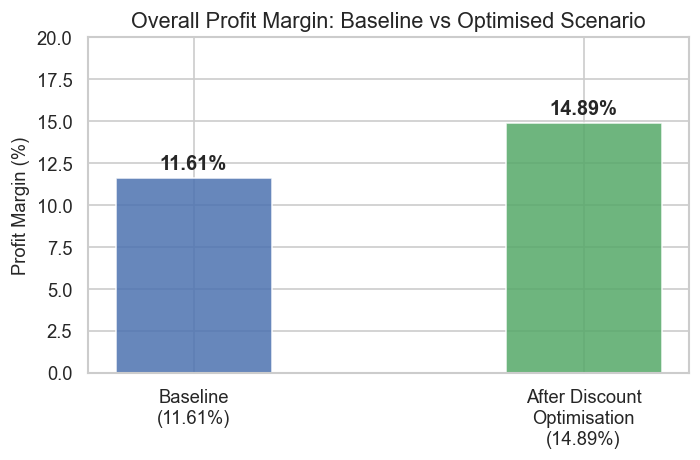


Conclusion: Implementing discount guardrails on the 9,845 over-discounted order lines
projects a +28% profit lift (~$414,820) with no change to product mix,
pricing architecture, or customer acquisition strategy.


In [25]:
# Final margin comparison visual
labels  = ['Baseline\n(11.61%)', 'After Discount\nOptimisation\n(14.89%)']
margins = [baseline_margin, new_margin]
colors  = ['#4C72B0', '#55A868']

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, margins, color=colors, width=0.4, alpha=0.85)
ax.set_ylabel('Profit Margin (%)')
ax.set_title('Overall Profit Margin: Baseline vs Optimised Scenario')
ax.set_ylim(0, 20)
for bar, val in zip(bars, margins):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.3, f'{val:.2f}%',
            ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nConclusion: Implementing discount guardrails on the 9,845 over-discounted order lines")
print(f"projects a +{profit_lift_pct:.0f}% profit lift (~${profit_lift_abs:,.0f}) with no change to product mix,")
print(f"pricing architecture, or customer acquisition strategy.")